# **Memprediksi Harga Hp Menggunakan Decesion Tree**

## **1.0 Bussines Understanding**

### **1.1 Latar Belakang**

Terdapat sebuah perusahan yang ingin memprediksi harga jual yang kompetitif dengan penjual lainnya

### **1.2 Tujuan**

Membangun model machine learning dengan menggunakan decession tree untuk memprediksi harga smartphone

### **1.3 Masalah**

Bagaimana cara menentukan harga jual yang kompetitif supaya tidak mengalami kebangkrutan

### **1.4 Solusi**

Membangun machine learning untuk memprediksi kelas harga

In [90]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [91]:
df = pd.read_csv('data_set.csv', na_values='.')
df.head(10)

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842.0,0.0,2.2,0.0,1.0,0.0,7.0,0.6,188.0,2.0,...,20.0,756.0,2549.0,9.0,7.0,19.0,0.0,0.0,1.0,1.0
1,1021.0,1.0,0.5,1.0,0.0,1.0,53.0,0.7,136.0,3.0,...,905.0,1988.0,2631.0,17.0,3.0,7.0,1.0,1.0,0.0,2.0
2,563.0,1.0,0.5,1.0,2.0,1.0,41.0,0.9,145.0,5.0,...,1263.0,NaN,2603.0,11.0,2.0,9.0,1.0,1.0,0.0,2.0
3,615.0,1.0,2.5,0.0,0.0,0.0,10.0,0.8,131.0,6.0,...,1216.0,1786.0,2769.0,16.0,8.0,11.0,1.0,0.0,0.0,2.0
4,1821.0,1.0,1.2,0.0,NaN,1.0,44.0,0.6,141.0,2.0,...,1208.0,1212.0,NaN,8.0,2.0,15.0,1.0,1.0,0.0,1.0
5,1859.0,0.0,0.5,1.0,3.0,0.0,22.0,0.7,164.0,1.0,...,1004.0,1654.0,1067.0,17.0,1.0,10.0,1.0,0.0,0.0,1.0
6,1821.0,0.0,NaN,0.0,4.0,1.0,10.0,0.8,139.0,8.0,...,381.0,1018.0,3220.0,13.0,8.0,18.0,1.0,0.0,1.0,3.0
7,1954.0,0.0,0.5,1.0,0.0,0.0,24.0,0.8,NaN,4.0,...,512.0,1149.0,700.0,16.0,3.0,5.0,1.0,1.0,1.0,0.0
8,1445.0,1.0,0.5,0.0,0.0,0.0,53.0,0.7,174.0,7.0,...,386.0,836.0,1099.0,17.0,1.0,20.0,1.0,0.0,0.0,0.0
9,509.0,1.0,0.6,1.0,2.0,1.0,9.0,0.1,93.0,5.0,...,1137.0,1224.0,513.0,19.0,10.0,12.0,1.0,0.0,0.0,0.0


In [92]:
df.info()
df.describe()
df.size

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  1960 non-null   float64
 1   blue           1960 non-null   float64
 2   clock_speed    1960 non-null   float64
 3   dual_sim       1960 non-null   float64
 4   fc             1960 non-null   float64
 5   four_g         1960 non-null   float64
 6   int_memory     1960 non-null   float64
 7   m_dep          1960 non-null   float64
 8   mobile_wt      1960 non-null   float64
 9   n_cores        1960 non-null   float64
 10  pc             1960 non-null   float64
 11  px_height      1960 non-null   float64
 12  px_width       1960 non-null   float64
 13  ram            1960 non-null   float64
 14  sc_h           1960 non-null   float64
 15  sc_w           1960 non-null   float64
 16  talk_time      1960 non-null   float64
 17  three_g        1960 non-null   float64
 18  touch_screen   1960

42000

In [93]:
df.isna().sum()
df.isna().sum().sum()

np.int64(820)

In [94]:
df.duplicated().sum()

np.int64(0)

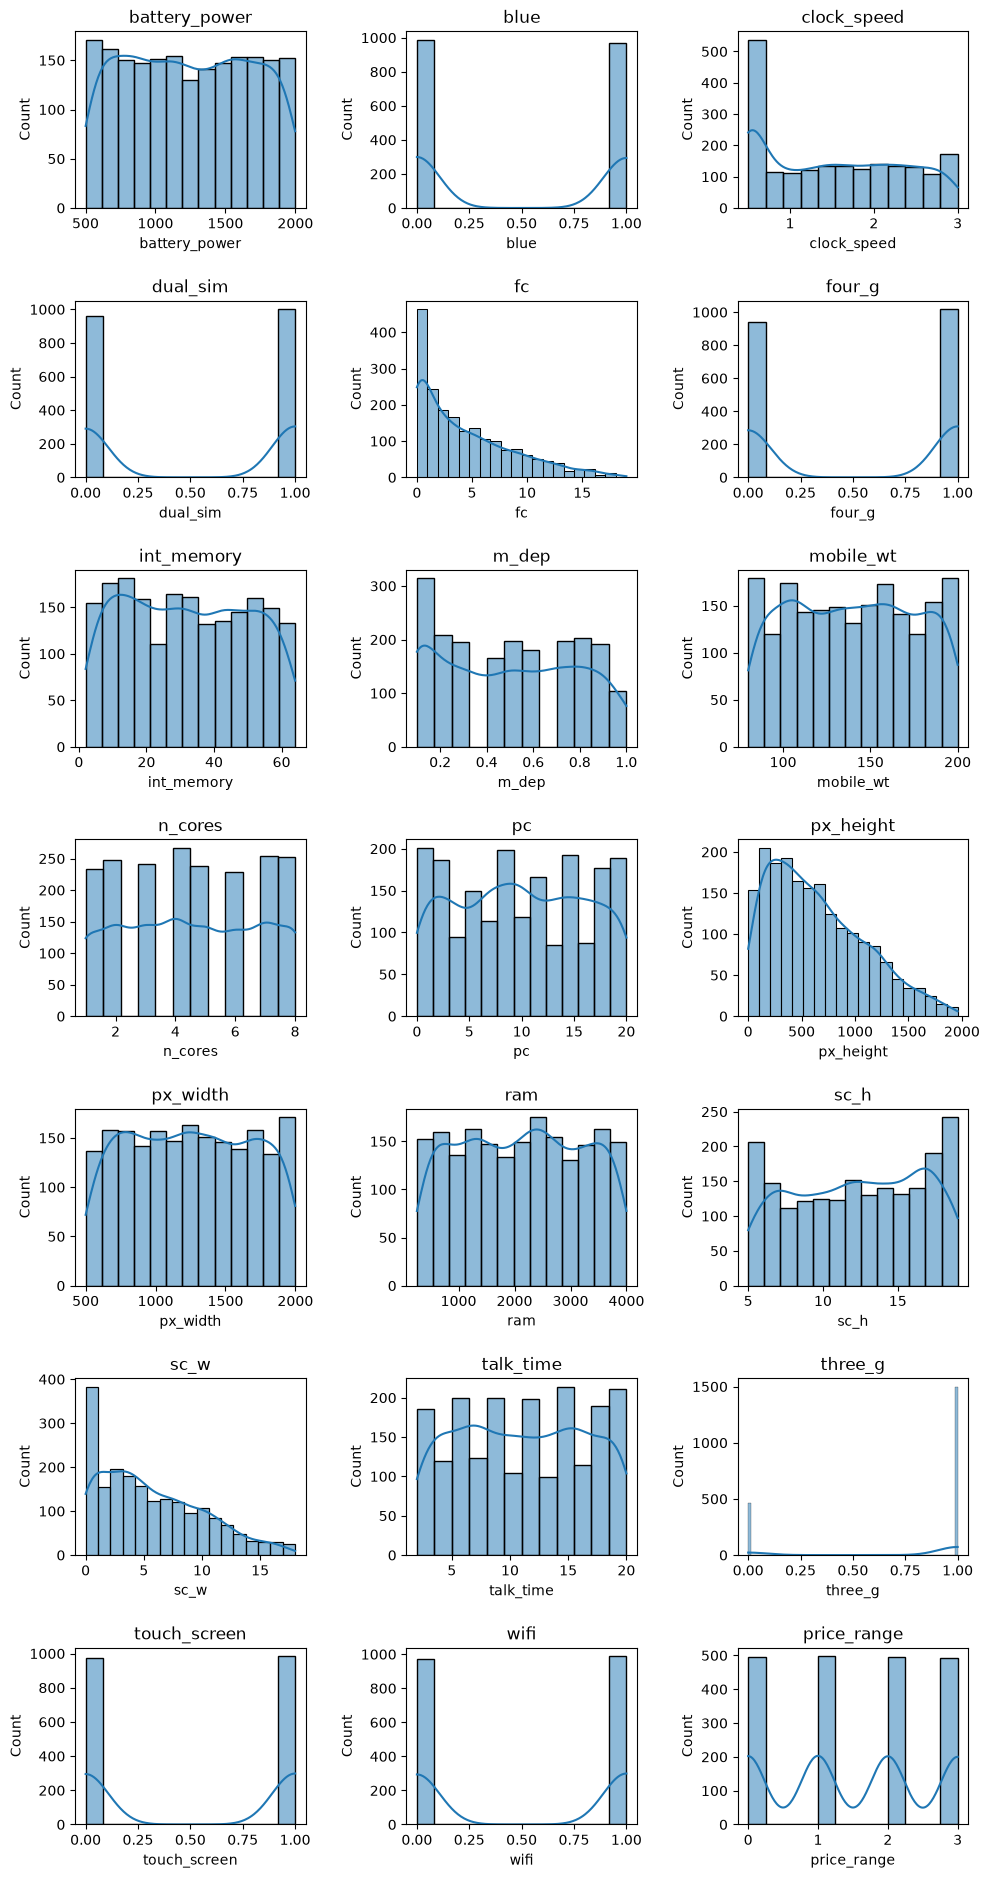

In [95]:
cols = df.select_dtypes(include='number').columns

plt.figure(figsize=(10, 40))

for i, cols in enumerate(cols, start=1):
    plt.subplot(15, 3, i)
    sns.histplot(df[cols], kde=True)
    plt.title(cols)

plt.tight_layout(h_pad=2, w_pad=2)
plt.show()

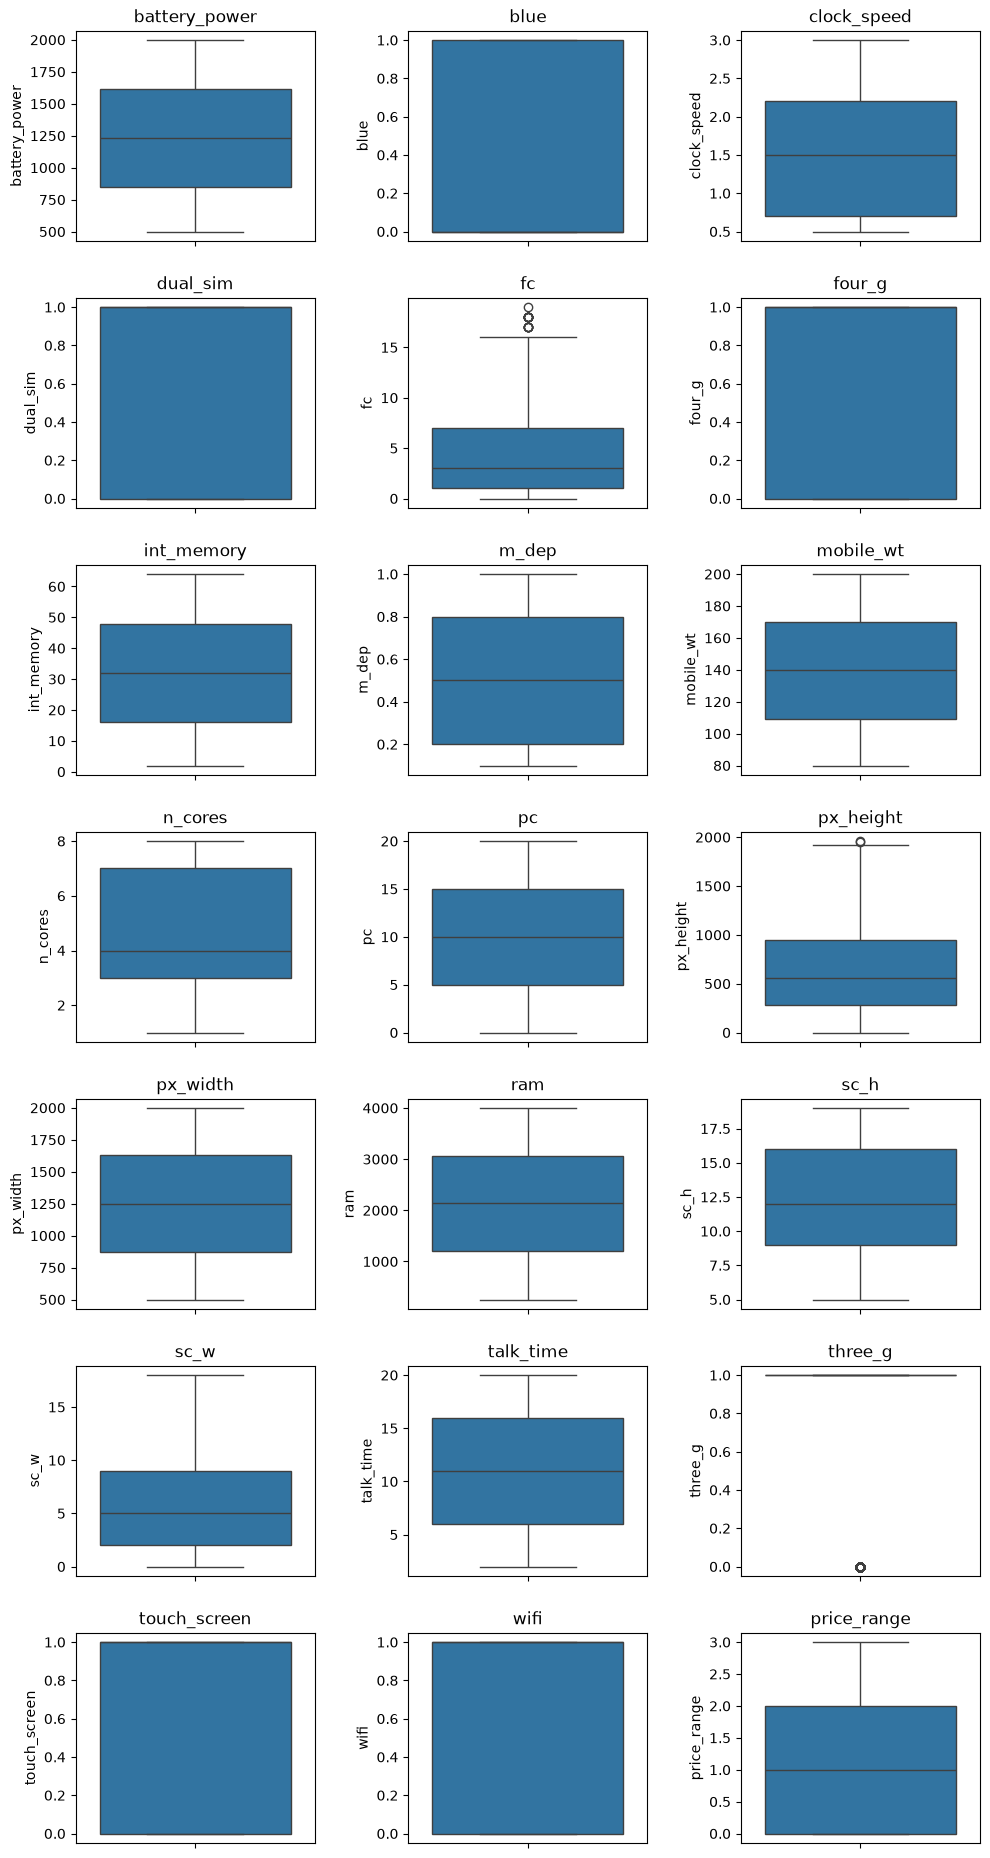

In [96]:
plt.figure(figsize=(10, 40))
cols = df.select_dtypes(include='number').columns


for i, cols in enumerate(cols, start=1):
    plt.subplot(15, 3, i)
    sns.boxplot(df[cols])
    plt.title(cols)

plt.tight_layout(h_pad=2, w_pad=2)
plt.show()

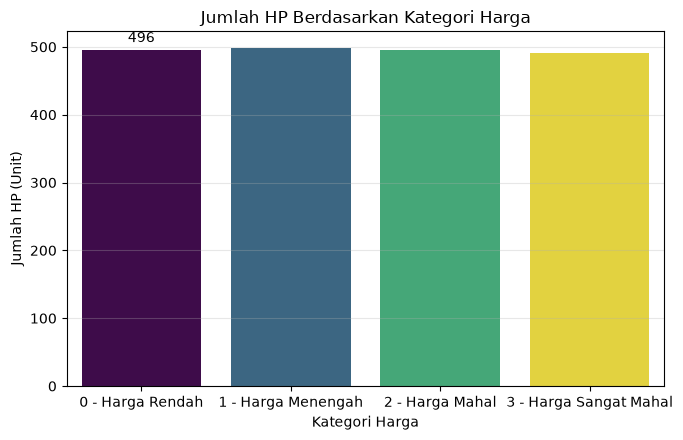

In [97]:
plt.figure(figsize=(7, 4.5))
label_harga = {0: 'Harga Rendah', 1: 'Harga Menengah', 2: 'Harga Mahal', 3: 'Harga Sangat Mahal'}
kategori = sorted(df['price_range'].dropna().unique())
labels = [str(int(k)) + ' - ' + label_harga.get(int(k), 'Lainnya') for k in kategori]

ax = sns.countplot(x='price_range', data=df, order=kategori,
                   hue='price_range', palette='viridis', legend=False)

plt.title('Jumlah HP Berdasarkan Kategori Harga')
plt.xlabel('Kategori Harga')
plt.ylabel('Jumlah HP (Unit)')
plt.xticks(ticks=range(len(kategori)), labels=labels)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

ax.bar_label(ax.containers[0], padding=3)
plt.show()


In [98]:
# Ringkasan jumlah data
print('Jumlah baris (data)  :', df.shape[0])
print('Jumlah kolom (fitur) :', df.shape[1])
print('Total sel            :', df.size)
print()

print('Jumlah data (non-kosong) tiap kolom:')
print(df.count())
print()

print('Jumlah data tiap kategori harga (price_range):')
jumlah = df['price_range'].value_counts().sort_index()
print(jumlah)
print()
print('Total seluruh data   :', int(jumlah.sum()))


Jumlah baris (data)  : 2000
Jumlah kolom (fitur) : 21
Total sel            : 42000

Jumlah data (non-kosong) tiap kolom:
battery_power    1960
blue             1960
clock_speed      1960
dual_sim         1960
fc               1960
four_g           1960
int_memory       1960
m_dep            1960
mobile_wt        1960
n_cores          1960
pc               1960
px_height        1960
px_width         1960
ram              1960
sc_h             1960
sc_w             1960
talk_time        1960
three_g          1960
touch_screen     1960
wifi             1960
price_range      1980
dtype: int64

Jumlah data tiap kategori harga (price_range):
price_range
0.0    496
1.0    498
2.0    495
3.0    491
Name: count, dtype: int64

Total seluruh data   : 1980


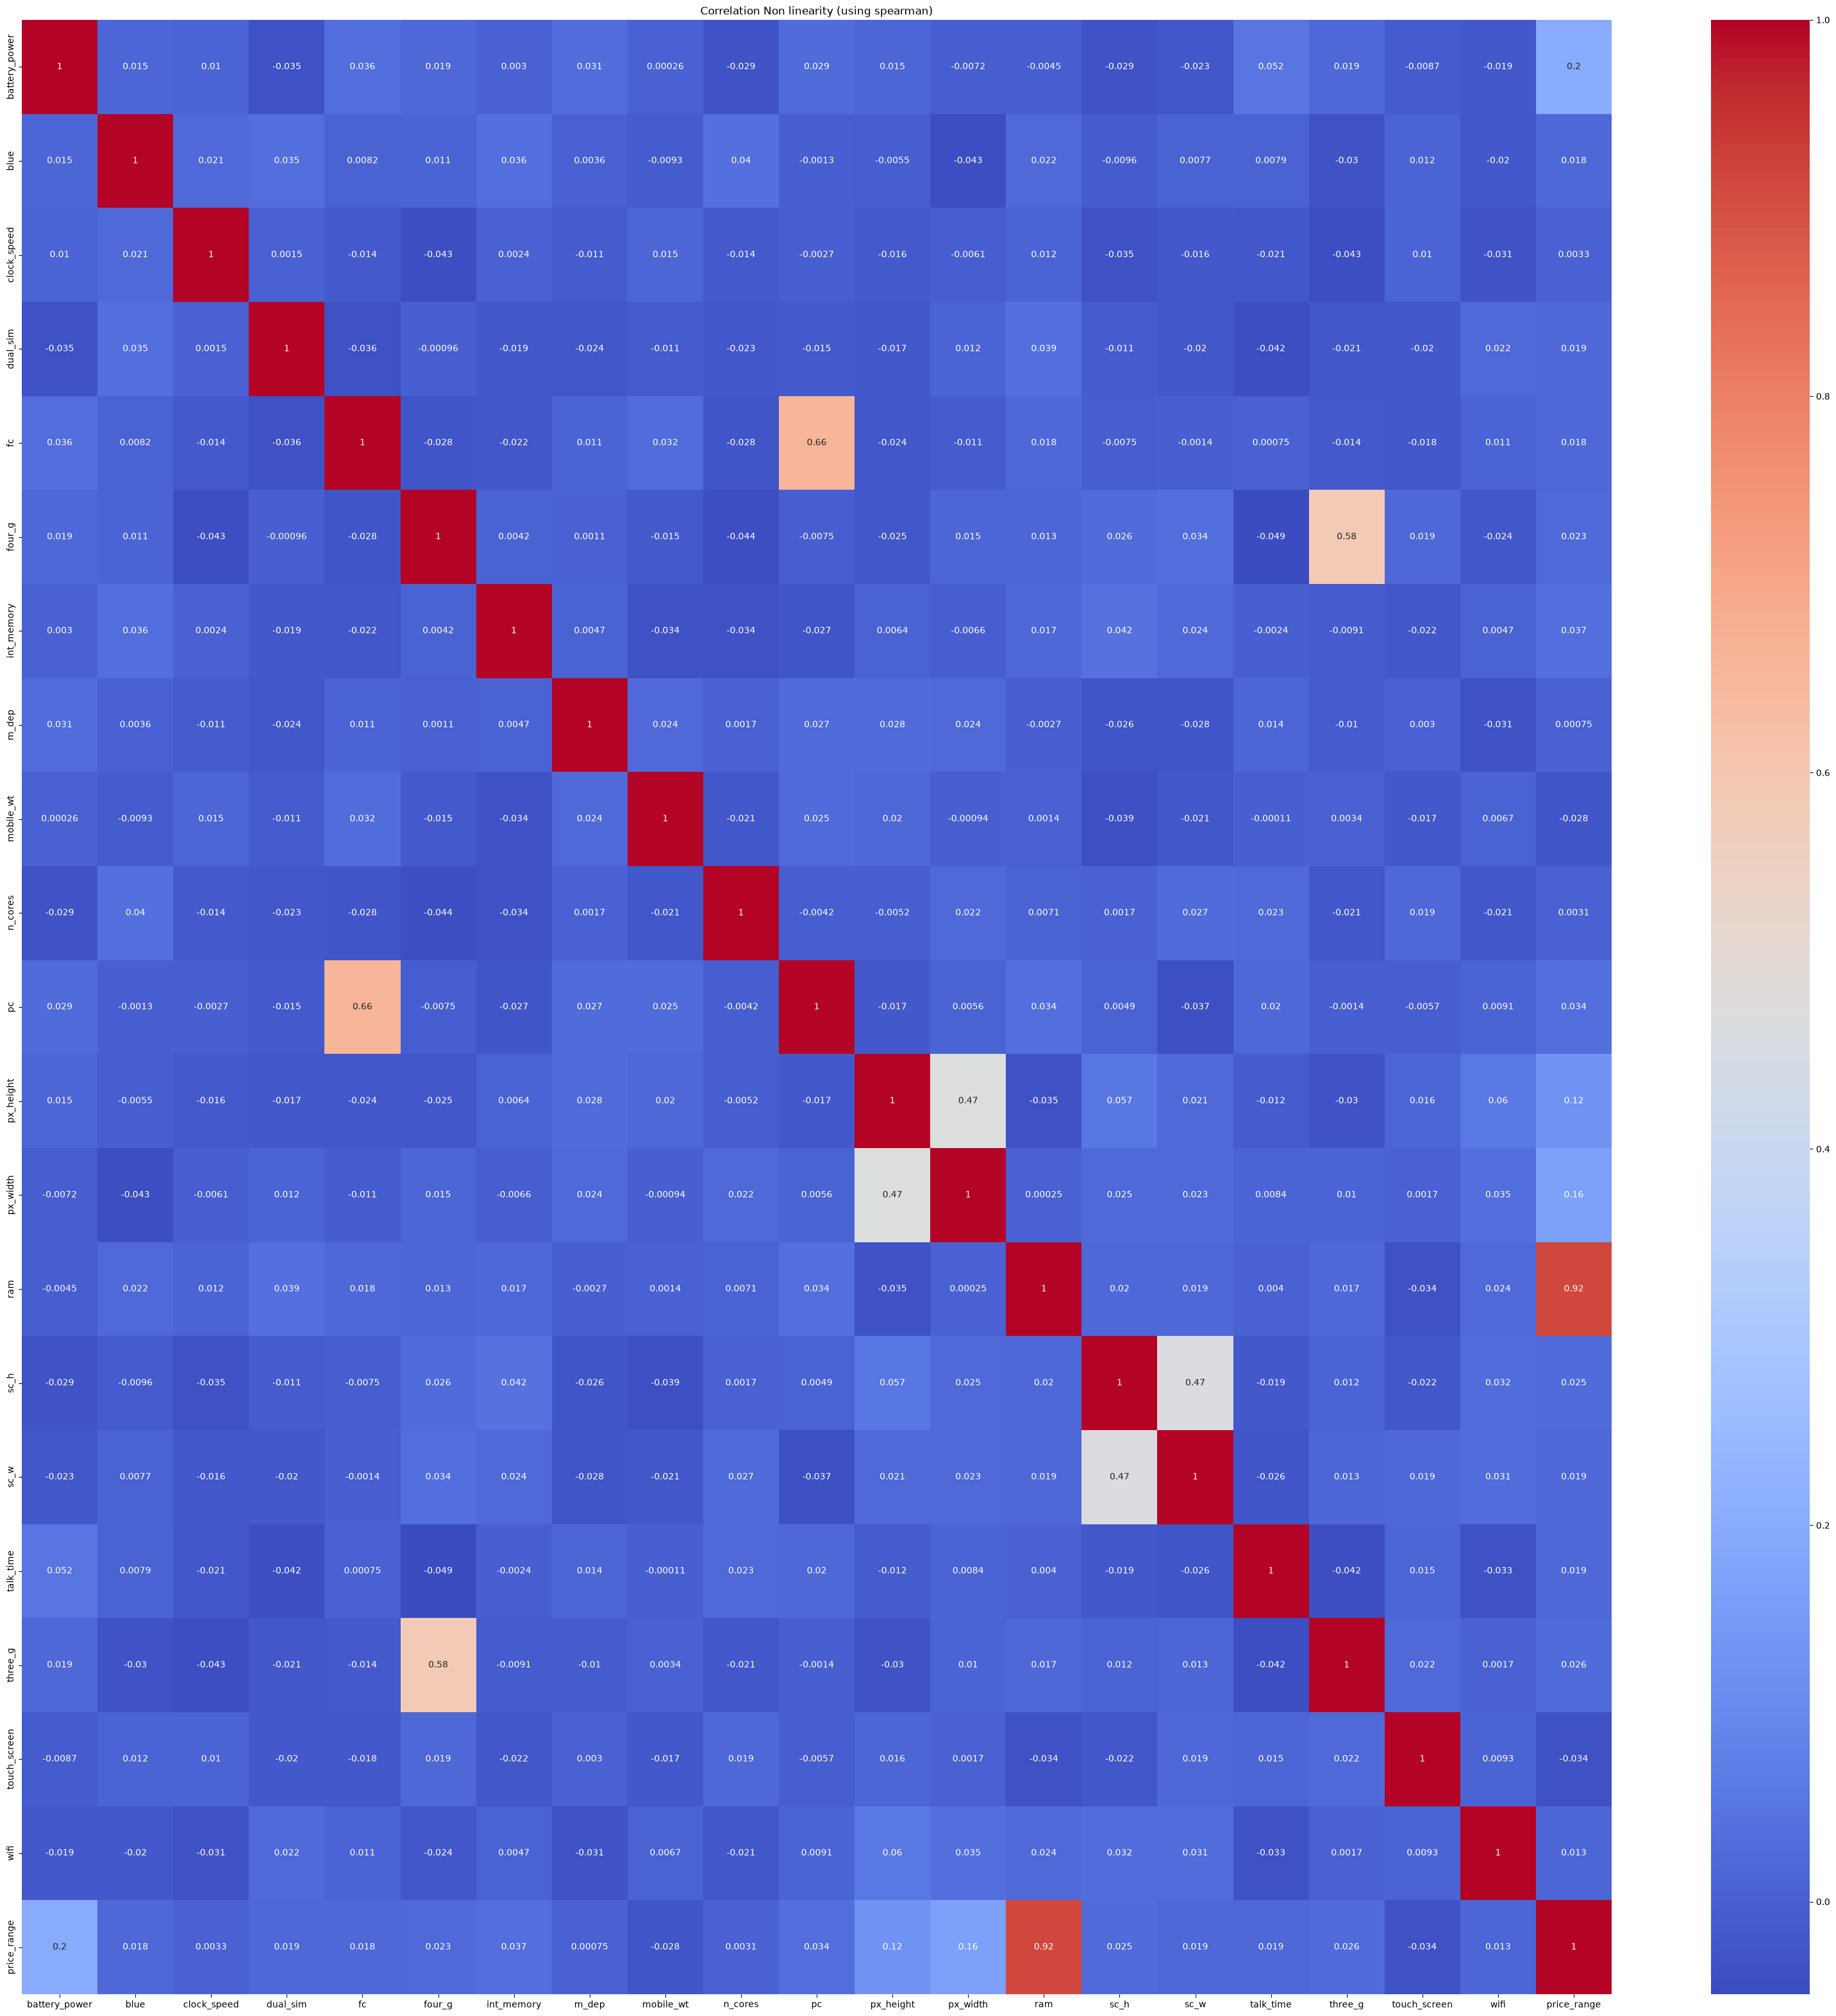

<Figure size 640x480 with 0 Axes>

In [99]:
plt.figure(figsize=(40, 40))
sns.heatmap(df.corr(method='spearman'), annot=True, cmap='coolwarm')
plt.title('Correlation Non linearity (using spearman)')
plt.show()
plt.tight_layout(w_pad=10, h_pad=10)

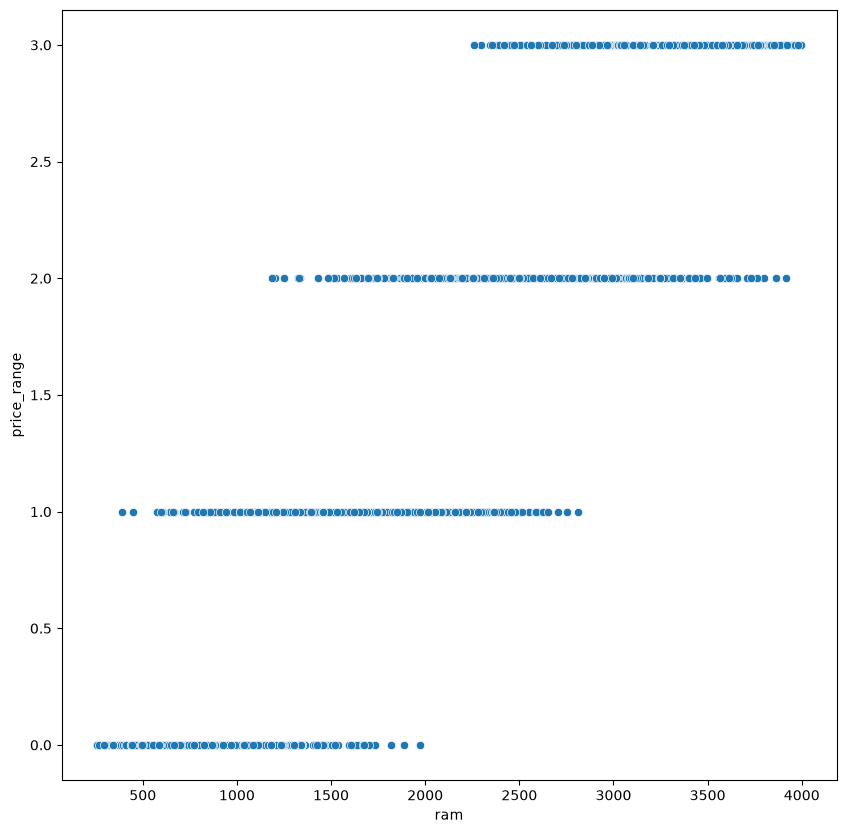

In [100]:
plt.figure(figsize=(10,10))

sns.scatterplot(df, x='ram', y='price_range')
plt.show()

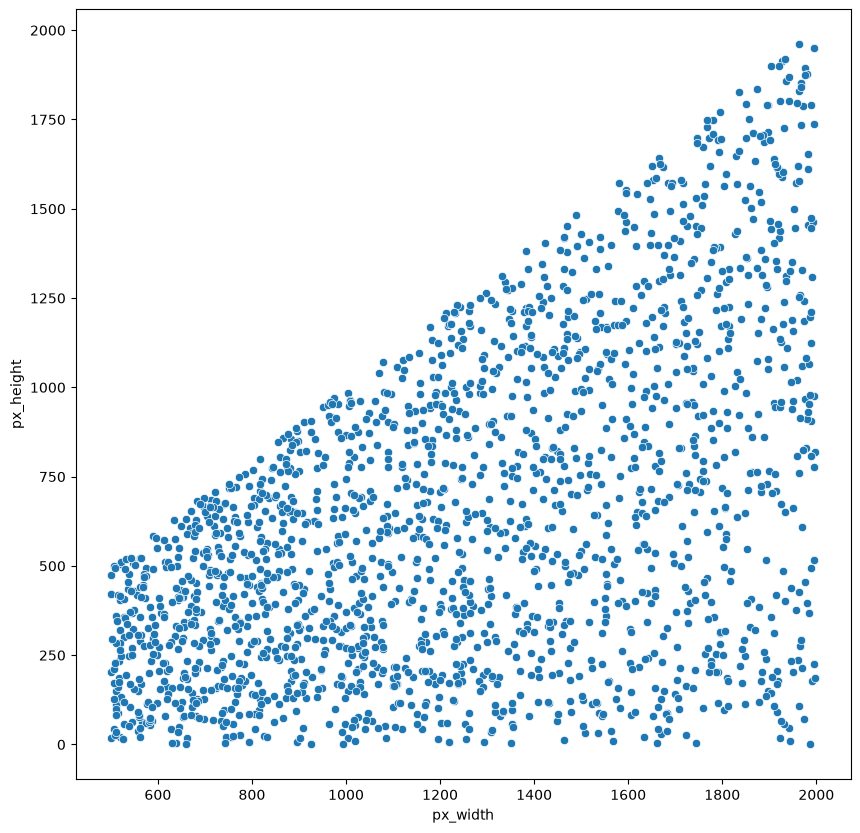

In [101]:
plt.figure(figsize=(10,10))

sns.scatterplot(df, x='px_width', y='px_height')
plt.show()

In [102]:
X = df.drop(columns=['price_range'])
y = df['price_range']

In [ ]:
def split_data (X,y,train_size=0.8, random_state=42):
    np.random.seed(random_state)
    idx = np.random.permutation(len(X))
    split_ratio = int(train_size * len(X))

    X_train , X_test = X.iloc[idx[:split_ratio]] , X.iloc[idx[split_ratio:]]
    y_train , y_test = y.iloc[idx[:split_ratio]] , y.iloc[idx[split_ratio:]]

    return X_train, X_test, y_train, y_test 

X_train, X_test, y_train, y_test = split_data(X, y)

In [111]:
Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)

IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR 

outlier = ((X_train < batas_bawah) | (X_train > batas_atas)).sum()

hasil = pd.DataFrame({'Outlier': outlier})
hasil.sort_values(by='Outlier', ascending=False)

,Outlier
three_g,372
fc,12
px_height,1
battery_power,0
dual_sim,0
clock_speed,0
blue,0
int_memory,0
m_dep,0
mobile_wt,0


In [105]:
# Mengambil modus dari y_train
mode_y = y_train.mode()[0]

# Mengisi missing value
y_train = y_train.fillna(mode_y)
y_test = y_test.fillna(mode_y)


# 1. Mengambil kolom numerik
num_cols = X_train.select_dtypes(include=['number']).columns

# 2. Mengisi missing value numerik menggunakan median
for col in num_cols:
    med = X_train[col].median()

    X_train[col] = X_train[col].fillna(med)
    X_test[col] = X_test[col].fillna(med)

In [106]:
null = pd.DataFrame({
    'X_train': X_train.isna().sum(),
    'X_test': X_test.isna().sum(),
    'y_test': y_test.isna().sum(),
    'y_train': y_train.isna().sum(),
})

null

,X_train,X_test,y_test,y_train
battery_power,0,0,0,0
blue,0,0,0,0
clock_speed,0,0,0,0
dual_sim,0,0,0,0
fc,0,0,0,0
four_g,0,0,0,0
int_memory,0,0,0,0
m_dep,0,0,0,0
mobile_wt,0,0,0,0
n_cores,0,0,0,0


In [107]:
X_train.head(20)

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
1860,1217.5,0.0,2.5,0.0,3.0,1.0,25.0,0.6,200.0,2.0,5.0,211.0,1608.0,686.0,8.0,6.0,11.0,1.0,1.0,0.0
353,1217.5,0.0,0.5,0.0,7.0,1.0,8.0,0.5,138.0,8.0,16.0,275.0,986.0,2563.0,19.0,17.0,19.0,1.0,0.0,0.0
1333,1217.5,0.0,2.9,0.0,9.0,0.0,14.0,0.4,196.0,7.0,18.0,293.0,952.0,1316.0,8.0,5.0,8.0,1.0,1.0,0.0
905,1217.5,1.0,2.0,0.0,4.0,0.0,17.0,0.2,166.0,3.0,19.0,256.0,1394.0,3892.0,18.0,7.0,19.0,1.0,1.0,0.0
1289,1217.5,1.0,0.5,1.0,7.0,0.0,58.0,0.5,130.0,5.0,8.0,1021.0,1958.0,1906.0,14.0,5.0,5.0,1.0,0.0,0.0
1273,1217.5,1.0,1.6,1.0,3.0,1.0,12.0,0.2,131.0,7.0,17.0,447.0,819.0,2476.0,13.0,1.0,10.0,1.0,0.0,0.0
938,1217.5,0.0,0.9,0.0,5.0,1.0,54.0,0.2,130.0,3.0,15.0,104.0,541.0,2829.0,11.0,5.0,13.0,1.0,0.0,1.0
1731,1217.5,0.0,3.0,1.0,6.0,1.0,5.0,0.5,167.0,5.0,7.0,53.0,1504.0,1044.0,8.0,7.0,11.0,1.0,0.0,0.0
65,1217.5,0.0,1.9,1.0,13.0,1.0,44.0,0.8,81.0,3.0,17.0,651.0,1618.0,3366.0,18.0,8.0,13.0,1.0,1.0,0.0
1323,1217.5,0.0,0.5,0.0,6.0,0.0,27.0,0.5,86.0,2.0,11.0,1245.0,1309.0,2001.0,11.0,10.0,12.0,1.0,1.0,1.0


In [108]:
# # 5. Mengubah DataFrame menjadi NumPy array
# X_train = X_train.values
# X_test = X_test.values

# y_train = y_train.values
# y_test = y_test.values

# print(X_train)
# print(y_train)
# print(X_test)
# print(y_test)